# 034 — CatBoost 031 + ensemble 025

Testa complementaridade com os componentes originais: ensemble 025 (XGBoost 200 árvores + MLP 64→32, dropout 0,1, inverse-sqrt, Adam 0,0001, batch 128, pesos internos 75/25) e CatBoost ponderado 031 (alpha 0,5 e parâmetros/restrições originais). Não incorpora automaticamente o vencedor do 033. Para cumprir a separação de decisões, o treino de 8.769 exemplos é estratificado em partição de ajuste dos componentes, partição independente para escolher época/iterações e partição independente para escolher mistura. A partição blend não é usada para early stopping. Misturas comparadas: 100/0, 90/10, 75/25, 50/50 e 0/100.

Cada pré-processador é ajustado apenas no respetivo treino; as probabilidades são alinhadas nas classes 0–15. Época e iterações são re-selecionadas internamente (não se impõem artificialmente os 85 períodos históricos do 025). A mistura é escolhida apenas por Macro F1 interna. Depois os componentes são reajustados nas 8.769 linhas e avaliados uma vez na validação fixa; para Kaggle, são reajustados nas 10.962 linhas completas e os pesos CatBoost recalculados no treino completo.

Sem uso de Kaggle para seleção; score Kaggle em branco. Preparação central, divisão fixa, exclusão de `AGE_RANGE`, `PID`, `HHID`, `PROXY`, `COUNTRY`, uma thread, parâmetros completos de recursos CatBoost preservados e checkpoints compatíveis com dados/código/parâmetros/versões. O resultado histórico 025 não registou versões de pacotes; as versões atuais são apresentadas nos outputs e coincidem com as registadas para 031/032. Validação fixa é desenvolvimento, não teste final independente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_033_034.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_033_034 import run_034, write_final_report, _package_versions

result = run_034()
print('Partições estratificadas:', result['three_way_split'])
print('Hashes de índices fit/seleção/blend:', result['three_way_split_index_sha256'])
print('Época MLP selecionada:', result['component_selection']['mlp_epoch'])
print('Iterações CatBoost selecionadas:', result['component_selection']['catboost_iterations'])
display(pd.DataFrame([{
    'Ensemble/CatBoost': row['weight_label'],
    'Macro F1 interna': row['internal_macro_f1'],
    'Accuracy interna': row['internal_metrics']['accuracy'],
} for row in result['blend_candidates']]))
print('Mistura escolhida exclusivamente na partição blend:', result['selected_internally']['weight_label'])
print('Configuração:', result['configuration'])
print('Versões do ambiente:', _package_versions())
print('Tempos (s):', result['training_seconds'])
print('Relatório atualizado:', write_final_report())

034: resultado reutilizado após validar dados, preparação, código, parâmetros e versões.
Partições estratificadas: {'fit': 6138, 'selection': 1315, 'blend': 1316}
Hashes de índices fit/seleção/blend: {'fit': '095a53fb4ce097788399ce6d8e695798a3401f8b3d62a25dc2701ad5218eeb0b', 'selection': '26b880c47fa23a0aa0bef83ada0682ad7cdbe2ca332bf4ca8b821d4c95ce9476', 'blend': 'bd012ea4080fc965625fc930052c5f6ba921cb76b9de590b1b2ad330560ddc50'}
Época MLP selecionada: 93
Iterações CatBoost selecionadas: 201


,Ensemble/CatBoost,Macro F1 interna,Accuracy interna
0,100%/0%,0.478222,0.483283
1,90%/10%,0.479952,0.484802
2,75%/25%,0.480704,0.484802
3,50%/50%,0.487244,0.486322
4,0%/100%,0.467678,0.468085


Mistura escolhida exclusivamente na partição blend: 50%/50%
Configuração: {'ensemble_025': {'xgboost': {'objective': 'multi:softprob', 'num_class': 16, 'tree_method': 'hist', 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'random_state': 42, 'n_jobs': 1, 'verbosity': 0}, 'mlp': {'architecture': [64, 32], 'dropout': 0.1, 'weighting': 'inverse_sqrt', 'learning_rate': 0.0001, 'batch_size': 128, 'max_epochs_for_internal_selection': 100, 'original_selected_epochs': 85, 'seed': 42}, 'internal_blend': [0.75, 0.25]}, 'catboost_031': {'depth': 4, 'learning_rate': 0.1, 'iterations': 262, 'class_weight_alpha': 0.5, 'max_iterations': 1000, 'early_stopping_rounds': 50, 'resource_parameters': {'boosting_type': 'Plain', 'max_ctr_complexity': 1, 'ctr_leaf_count_limit': 256, 'border_count': 32, 'one_hot_max_size': 10, 'counter_calc_method': 'SkipTest', 'rsm': 0.2, 'leaf_estimation_iterations': 1, 'used_ram_limit': '512mb'}}, 'blend_weights_ensemble_catboost': [[1.0, 0.0], [0.9, 0.1], [0.75,

In [2]:
fixed = result['fixed_metrics']
print('Treino 8.769 linhas:', {k: fixed['train'][k] for k in ('macro_f1', 'accuracy')})
print('Validação fixa:', {k: fixed['validation'][k] for k in ('macro_f1', 'accuracy')})
class_metrics = pd.DataFrame(fixed['validation']['per_class'])
class_metrics['destacada'] = class_metrics['classe'].map({1: 'CHAVE', 6: 'CHAVE', 13: 'CHAVE'}).fillna('')
display(class_metrics[['classe', 'escalão', 'F1', 'recall', 'support', 'destacada']])
display(pd.DataFrame([
    {'componente': name, 'Macro F1 validação': row['validation']['macro_f1'], 'accuracy validação': row['validation']['accuracy']}
    for name, row in result['component_fixed_validation_metrics'].items()
]))
print('Kaggle score: — (não submetido)')
print('Submissão:', result['submission'])
print('Diferenças face aos CSVs anteriores:', result['submission']['differences'])

Treino 8.769 linhas: {'macro_f1': 0.8890596868050777, 'accuracy': 0.8720492644543277}
Validação fixa: {'macro_f1': 0.4606811845573979, 'accuracy': 0.466484268125855}


,classe,escalão,F1,recall,support,destacada
0,0,15–17 anos,0.813953,0.853659,41,
1,1,18–19 anos,0.451613,0.411765,34,CHAVE
2,2,20–24 anos,0.583851,0.587500,80,
3,3,25–29 anos,0.312925,0.306667,75,
4,4,30–34 anos,0.241611,0.200000,90,
5,5,35–39 anos,0.365591,0.395349,129,
6,6,40–44 anos,0.404558,0.412791,172,CHAVE
7,7,45–49 anos,0.391304,0.364162,173,
8,8,50–54 anos,0.625954,0.679558,181,
9,9,55–59 anos,0.628713,0.625616,203,


,componente,Macro F1 validação,accuracy validação
0,ensemble_025,0.459143,0.462836
1,catboost_031,0.450809,0.450980


Kaggle score: — (não submetido)
Submissão: {'path': 'submissions/submission_034_ensemble_catboost_ponderado.csv', 'duplicate_of': [], 'differences': {'submission_001_regressao_logistica.csv': 1448, 'submission_002_regressao_logistica_regularizada.csv': 1208, 'submission_004_arvore_decisao.csv': 2069, 'submission_007_xgboost.csv': 632, 'submission_010_mlp_pytorch.csv': 1343, 'submission_012_mlp_perda_ponderada.csv': 1404, 'submission_014_xgboost_mlp.csv': 527, 'submission_015_mlp_learning_rate.csv': 1234, 'submission_016_xgboost_mlp015.csv': 502, 'submission_017_mlp_ponderacao_suave.csv': 1181, 'submission_018_mlp_sgd.csv': 1394, 'submission_019_ensemble_pesos.csv': 598, 'submission_020_mlp_dropout.csv': 1157, 'submission_021_mlp_sgd_ponderacao_suave.csv': 1260, 'submission_025_xgboost_mlp_dropout.csv': 451, 'submission_028_ensemble_features_dominio.csv': 650, 'submission_029_catboost.csv': 873, 'submission_031_catboost_ponderacao_suave.csv': 798}, 'reason': None, 'rows': 3655, 'columns

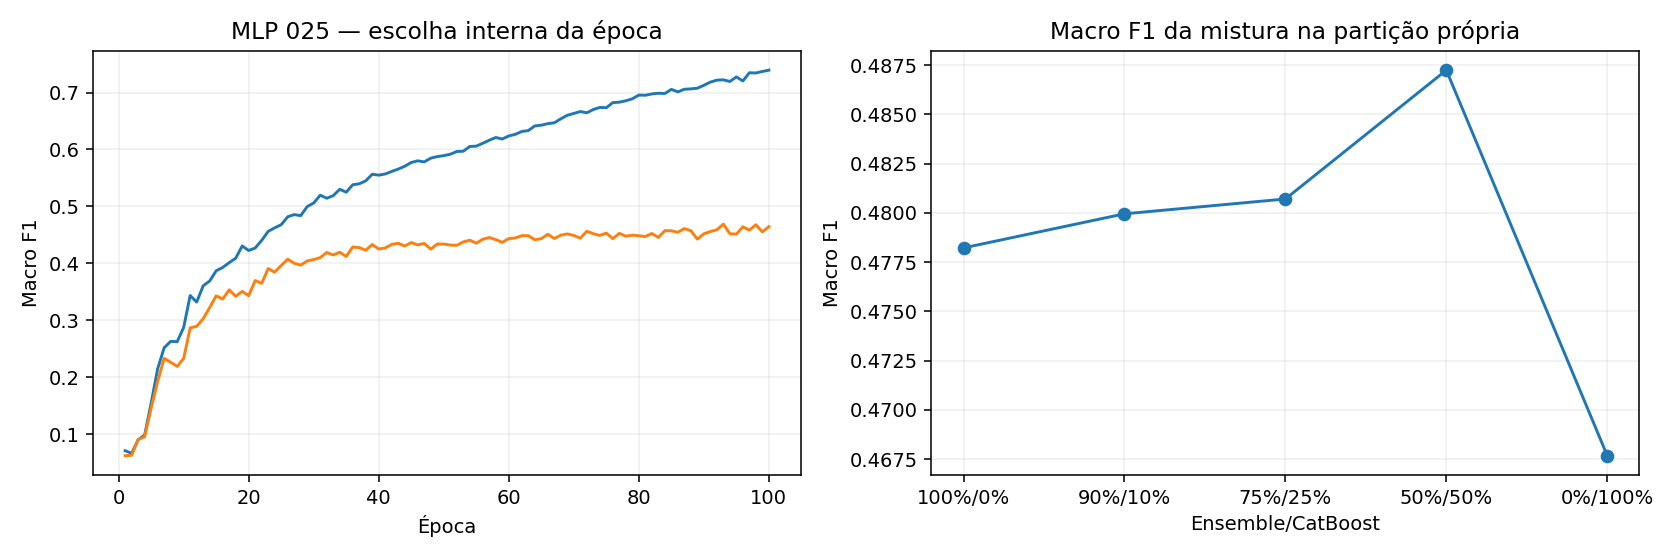

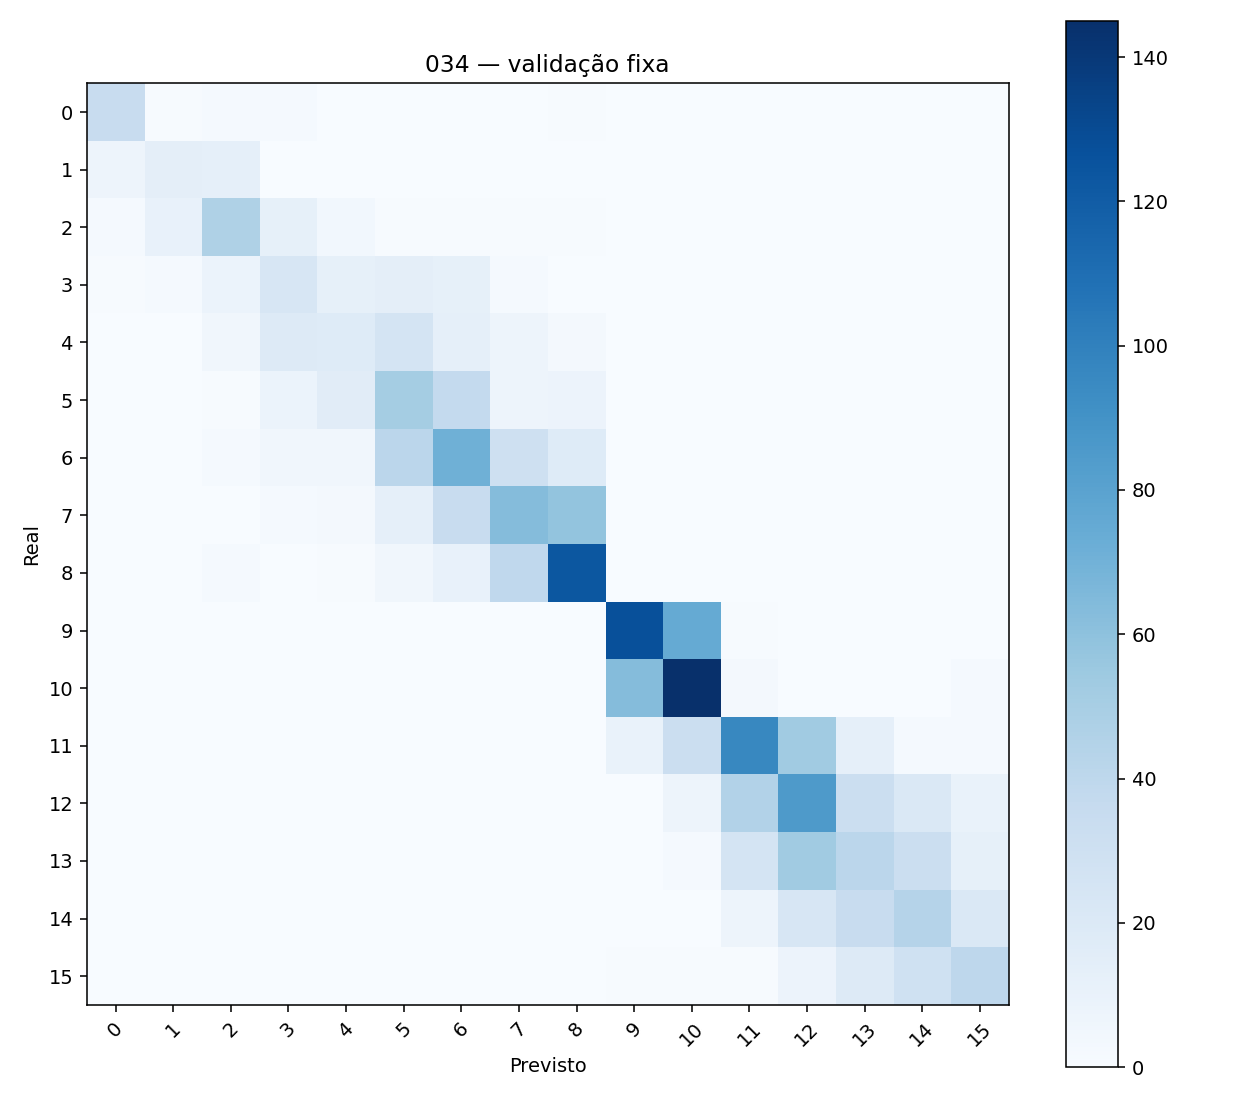

In [3]:
display(Image(filename=str(root / result['curves'])))
display(Image(filename=str(root / result['confusion_matrix'])))

## Conclusão
- Data:16/11
- Pontuação Kaggle: 0.46
- Conclusão: abaixo do ensemble 025 (0,48) e do CatBoost 031 (0,47). A mistura 50/50 não melhorou os resultados; mantemos o 025 como referência.
- Melhorias: testar uma contribuição menor do CatBoost, escolhida internamente, e comparar nos mesmos folds. Depois desta sequência, daria prioridade a estabilizar a validação antes de continuar a afinar misturas.
